# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+

NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [2]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from scipy import stats

### Cargar Dataset

In [3]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 15000 entries, 0 to 14999
,Data columns (total 12 columns):
, #   Column                     Non-Null Count  Dtype  
,---  ------                     --------------  -----  
, 0   id_cliente                 15000 non-null  object 
, 1   edad                       15000 non-null  float64
, 2   nivel_ingreso              15000 non-null  float64
, 3   visitas_mes                15000 non-null  int64  
, 4   compras_mes                15000 non-null  int64  
, 5   gasto_publicidad_dirigida  15000 non-null  float64
, 6   satisfaccion               15000 non-null  float64
, 7   miembro_premium            15000 non-null  int64  
, 8   abandono                   15000 non-null  int64  
, 9   tipo_dispositivo           15000 non-null  object 
, 10  region                     15000 non-null  object 
, 11  ingreso_anual              15000 non-null  float64
,dtypes: float64(5), int64(4), object(3)
,memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [4]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [5]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [6]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 15000 entries, 0 to 14999
,Data columns (total 12 columns):
, #   Column                     Non-Null Count  Dtype  
,---  ------                     --------------  -----  
, 0   id_cliente                 15000 non-null  object 
, 1   edad                       15000 non-null  int64  
, 2   nivel_ingreso              15000 non-null  float64
, 3   visitas_mes                15000 non-null  int64  
, 4   compras_mes                15000 non-null  int64  
, 5   gasto_publicidad_dirigida  15000 non-null  float64
, 6   satisfaccion               15000 non-null  float64
, 7   miembro_premium            15000 non-null  int64  
, 8   abandono                   15000 non-null  int64  
, 9   tipo_dispositivo           15000 non-null  object 
, 10  region                     15000 non-null  object 
, 11  ingreso_anual              15000 non-null  float64
,dtypes: float64(4), int64(5), object(3)
,memory usage: 1.4+ MB


#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
variables_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
df[variables_numericas].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

,count,mean,std,min,50%,max
edad,15000.0,38.262400,11.492378,18.0,38.000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,30023.745,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,10.000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,1.000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,19.730,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.600,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,30.705,244.69


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` presenta números enteros, y nos muestra que la edad mas grande de registro es de 75 y la menor es de 18 años.
- `compras_mes` y `gasto_publicidad_dirigida` presentan una fuerte dispersión a la derecha.  
- `ingreso_anual` muestra valores de 0 en clientes sin compras registradas

#### Explorar variables binarias

In [8]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df[['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']].describe())

               edad  nivel_ingreso   visitas_mes   compras_mes  \
,count  15000.000000   15000.000000  15000.000000  15000.000000   
,mean      38.262400   30019.704782     10.029000      1.206467   
,std       11.492378    9833.166305      3.158189      1.105284   
,min       18.000000    8000.000000      1.000000      0.000000   
,25%       30.000000   23127.097500      8.000000      0.000000   
,50%       38.000000   30023.745000     10.000000      1.000000   
,75%       46.000000   36768.440000     12.000000      2.000000   
,max       75.000000   74790.840000     25.000000      8.000000   
,
,       gasto_publicidad_dirigida  satisfaccion  ingreso_anual  
,count               15000.000000  15000.000000   15000.000000  
,mean                   20.149301      3.603693      36.594180  
,std                    10.880724      0.685300      34.484888  
,min                     0.000000      1.000000       0.000000  
,25%                    12.310000      3.100000       0.000000  
,50%  

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` y `abandono` están codificadas como 0/1. La proporción de miembros premium y tasa de abandono permite comparar directamente retención e ingresos.

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
print(df[['miembro_premium', 'abandono']].value_counts())

miembro_premium  abandono
,0                0           10741
,                 1            2170
,1                0            1998
,                 1              91
,dtype: int64


In [10]:
# Explorar variables categóricas y cómo se distribuyen
print(df['tipo_dispositivo'].value_counts())
print(df['region'].value_counts())

móvil         9818
,escritorio    3720
,tablet        1462
,Name: tipo_dispositivo, dtype: int64
,norte    4395
,oeste    3810
,sur      3726
,este     3069
,Name: region, dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` (movil, escritorio, tablet) y
- `region` (norte, sur, este, oeste) distribuidas equitativamente. 

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

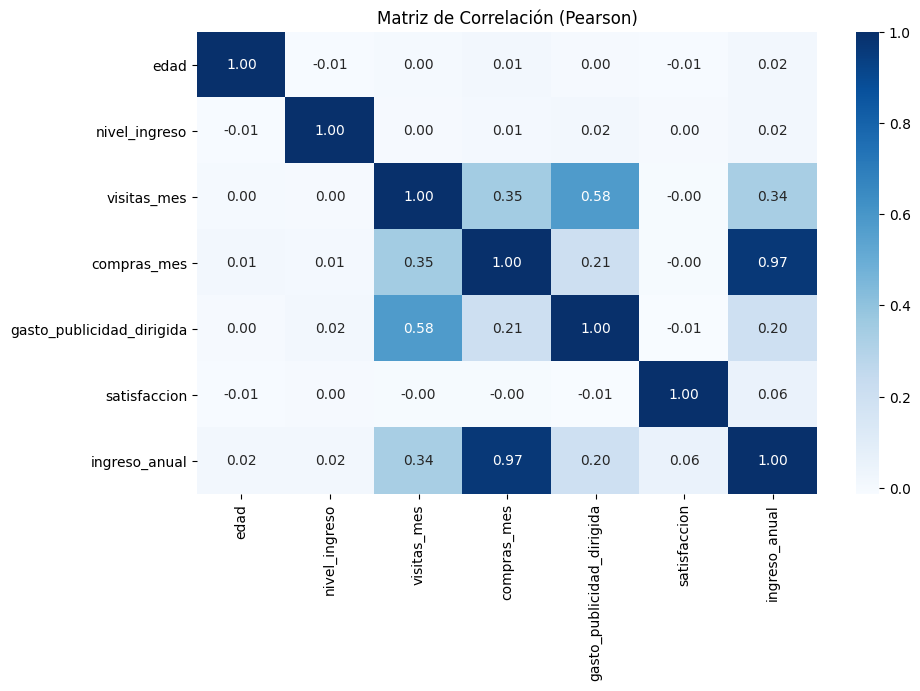

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
plt.figure(figsize=(10, 6))
numeric_cols = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title('Matriz de Correlación (Pearson)')
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa una independencia casi total entre las variables demográficas (edad, nivel_ingreso) y las variables de comportamiento o satisfacción, con coeficientes cercanos a 0.00
- Existe una relación positiva moderada entre visitas_mes y gasto_publicidad_dirigida (0.58), lo que sugiere que la inversión publicitaria logra atraer más visitas a la plataforma.
- visitas_mes guarda una relación positiva moderada con compras_mes (0.35), indicando que mayor tráfico se traduce parcialmente en transacciones.


Observaciones respecto a `ingreso_anual`  
- Presenta una correlación positiva muy fuerte de 0.97 con compras_mes, posicionándola como la variable principal asociada al volumen de ingresos generados.
- Presenta una correlación positiva moderada-baja con visitas_mes (0.34) y gasto_publicidad_dirigida (0.20).
- Muestra una asociación prácticamente nula o insignificante con satisfaccion (0.06), edad (0.02) y nivel_ingreso (0.02).


### Scatterplot general



Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.
  - NO GENERAR EL SCATTERPLO GENERAL.
  - Ruidoso y redundante: Un pairplot o scatterplot general involucra una matriz de 7x7 gráficos (49 subgráficos en total). La gran mayoría de estas combinaciones (como edad vs. nivel_ingreso o satisfaccion vs. visitas_mes) presentan correlaciones prácticamente nulas ($r \approx 0.00$), por lo que graficarlas genera dispersión uniforme sin aportar valor interpretativo.



### Scatterplot para pares clave

Text(0.5, 1.0, 'Gasto Publicidad Dirigida vs Ingreso Anual')

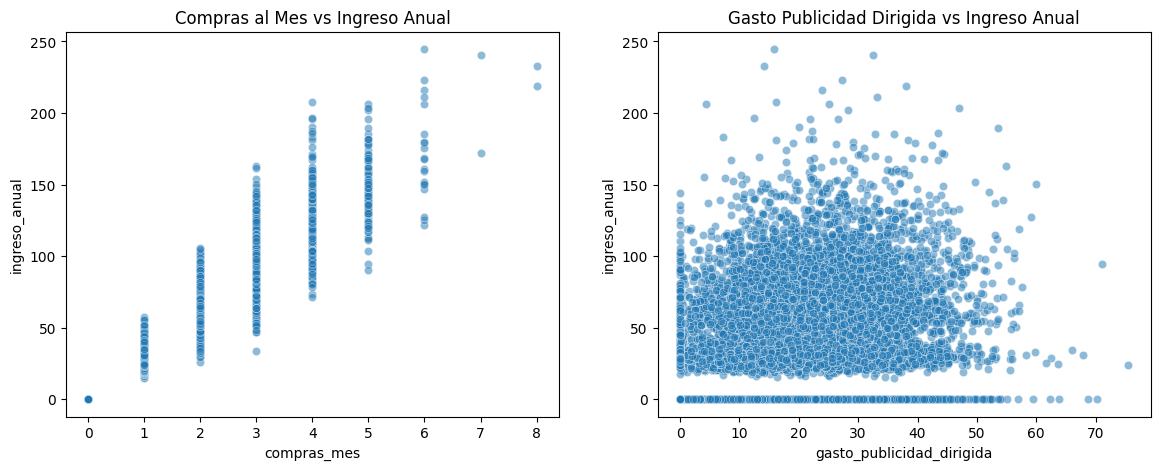

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual', ax=axes[0], alpha=0.5)
axes[0].set_title('Compras al Mes vs Ingreso Anual')
sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='ingreso_anual', ax=axes[1], alpha=0.5)
axes[1].set_title('Gasto Publicidad Dirigida vs Ingreso Anual')

In [13]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección: Positiva.
- Dispersión: Baja.
- Los puntos siguen una clara tendencia ascendente por niveles discretos de compras.
- Outliers: Se observan algunos valores atípicos en la parte superior derecha (usuarios con 6 a 8 compras e ingreso anual superior a $200).
- Colinealidad: Presenta una asociacion lineal extremadamente alta, lo que indica una fuerte dependencia direecta entre ambas métricas.  

**gasto_publicidad_dirigida vs ingreso_anual**
- Dirección: Positiva débil.
- Dispersión: Alta.
- Los datos forman una nube dispersa a lo largo de todo el rango de gasto.
- Outliers: Presencia notable de valores atípicos con ingresos altos ($>200$) en niveles moderados de gasto publicitario, además de una línea de clientes en $0.00$ de ingreso sin importar la cantidad invertida en publicidad.
- Colinealidad: No se observa colinealidad significativa ($r = 0.20$); la inversión en publicidad por sí sola no predice de forma lineal el ingreso anual generado.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [14]:
# Calcular correlación entre variables relevantes
pearson_corr = df[numeric_cols].corr(method='pearson')['ingreso_anual']
spearman_corr = df[numeric_cols].corr(method='spearman')['ingreso_anual']

In [15]:
# Calcular correlación entre variables relevantes
corr_summary = pd.DataFrame({'Pearson': pearson_corr, 'Spearman': spearman_corr})
print(corr_summary)

                            Pearson  Spearman
,edad                       0.017496  0.016097
,nivel_ingreso              0.017446  0.025017
,visitas_mes                0.337147  0.320954
,compras_mes                0.967149  0.967482
,gasto_publicidad_dirigida  0.197483  0.184999
,satisfaccion               0.056171  0.060834
,ingreso_anual              1.000000  1.000000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**compras_mes vs ingreso_anual**
- Pearson: 0.967149 y spearman: 0.967482, tienen una magnitud extremadamente fuerte, lo que nos indica que la relación es directa y lineal, lo que indica que existe una alta probabilidad de colinealidad.


**satisfaccion vs ingreso_anual**
- Correlación de Pearson: 0.056171 y spearman: 0.060834 la magnitud es minima, casi insignificante, casi no nos aporta información lineal sobre el ingreso anual

**visitas_mes vs ingreso_anual**
- Correlación de Pearson: 0.337147 y spearmam: 0.320954 la relación es morerada con tendecia debil al registrar mayor ingreso anual conforme aumentan las visitas mensuales.


### Punto-biserial

In [48]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

for bin_var in ['miembro_premium', 'abandono']:
    corr, p_val = pointbiserialr(df[bin_var], df['ingreso_anual'])
    print(f'Punto-biserial ({bin_var} vs ingreso_anual): r = {corr:.3f}, p-value = {p_val:.4e}')

Punto-biserial (miembro_premium vs ingreso_anual): r = 0.093, p-value = 3.0943e-30
,Punto-biserial (abandono vs ingreso_anual): r = -0.003, p-value = 7.2947e-01


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   

Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**
- Relación: Positiva de magnitud baja ($r \approx 0.09$, $p < 0.001$). Indica que ser miembro premium se asocia de forma ligera pero estadísticamente significativa con un mayor ingreso anual generado para la empresa.

**abandono vs ingreso_anual**
- Relación: Negativa de magnitud prácticamente nula e insignificante ($r \approx -0.003$, $p > 0.05$). No existe una correlación lineal relevante entre si un cliente abandonó la plataforma y el total de ingresos registrados en el periodo.


### V de Cramér

In [23]:
# Función para calcular V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min((k - 1), (r - 1)))

In [24]:
# Aplicar V de Cramér en variables relevantes
print("Cramér V (tipo_dispositivo vs region):", cramers_v(df['tipo_dispositivo'], df['region']))


Cramér V (tipo_dispositivo vs region): 0.012378338407739397


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér

- Magnitud de la asociación: Prácticamente nula ($V \approx 0.012$). La correlación entre el tipo de dispositivo utilizado (móvil, escritorio, tablet) y la región geográfica del cliente (norte, sur, este, oeste) es extremadamente débil.  
- Significancia estadística: No existe dependencia entre ambas variables ($p > 0.05$). La distribución de los dispositivos es homogénea y equitativa a lo largo de todas las regiones geográficas.
- Implicación: No se requiere una estrategia de segmentación o personalización técnica adaptada a plataformas específicas por región geográfica. 


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### HALLAZGO 1

### Volumen de Compras Mensuales
  
**Evidencia numérica**

Alta correlación entre compras_mes e ingreso_anual

**Interpretación**  
Los clientes que realizan un número elevado de transacciones al mes se asocian con el mayor volumen de ingresos hablando anualmente.

**No podemos afirmar**  
Que forzar más compras mediante spam vaya a incrementar directamente el valor de vida del cliente.

**Implicación de negocio**  
Incentivar la frecuencia de compra mediante programas de lealtad y recompensas por recurrencia.

### HALLAZGO 2

### Suscripción Premium
  
**Evidencia numérica:** 
Correlación punto-biserial positiva entre miembro_premium e ingreso_anual.

**Interpretación**  
Los usuarios con membresía premium aportan un ingreso menor en comparación con los usuarios estándar, aunque la relacion que proporcionan estadisticamente es significativa por el tipo de muestra, su magnitud es pequeña. 

**No podemos afirmar**  
Que la suscripción sea la causa directa del mayor gasto; puede responder a un sesgo de selección de usuarios previamente de alto valor.

**Implicación de negocio**  
Diseñar pruebas gratuitas (free trials) de la membresía premium para convertir usuarios recurrentes.


## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- Correlación ≠ causalidad
- Posibles variables omitidas

### **Próximos pasos** 

Probar segmentación adicional
- Clasificar usuarios por Recencia
- Frecuencia
- Valor Monetario.

Experimentos A/B
- Probar ofertas de suscripción Premium en clientes con alto compras_mes no premium.

Modelo Predictivo
- Construir un modelo de regresión para estimar el valor del cliente (CLV).